In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PowerTransformer
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv("voxceleb_vectors33.csv")

In [4]:
print(" Dataset Shape:", df.shape)
print("\n Missing Values:\n", df.isnull().sum())

 Dataset Shape: (12105, 161)

 Missing Values:
 f0       0
f1       0
f2       0
f3       0
f4       0
        ..
f156     0
f157     0
f158     0
f159     0
label    0
Length: 161, dtype: int64


Numeric Feature Distribution

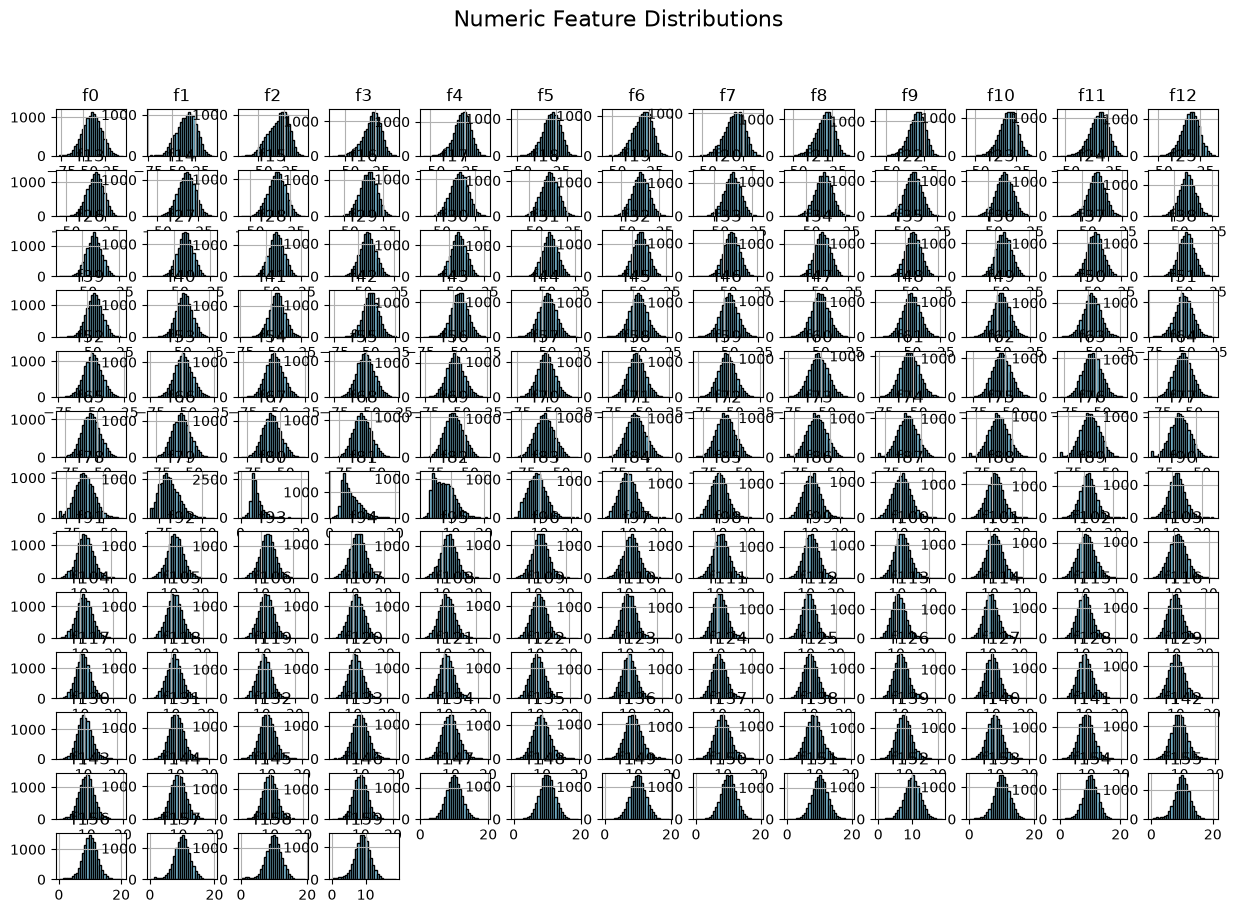

In [5]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

df[numeric_cols].hist(bins=30, figsize=(15, 10), color='skyblue', edgecolor='black')
plt.suptitle("Numeric Feature Distributions", fontsize=16)
plt.show()

Categorical Feature Distribution

C:\Users\Sakshi Jha\AppData\Local\Temp\ipykernel_27192\1123334361.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns
C:\Users\Sakshi Jha\AppData\Local\Temp\ipykernel_27192\1123334361.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette="viridis")


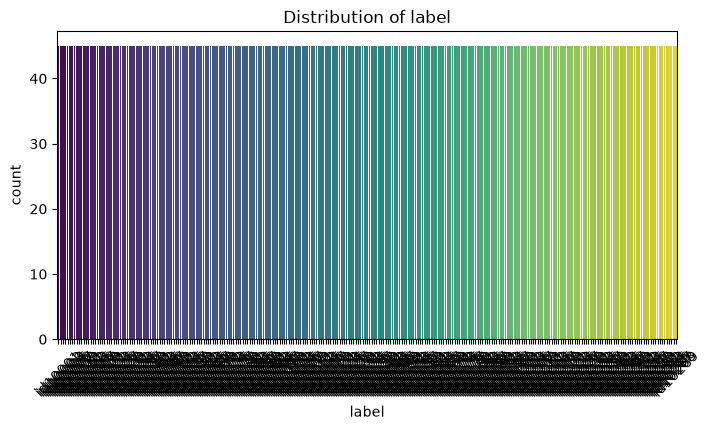

In [6]:
cat_cols = df.select_dtypes(include=['object', 'category']).columns

for col in cat_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, palette="viridis")
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.show()

Target Variable Distribution

C:\Users\Sakshi Jha\AppData\Local\Temp\ipykernel_27192\588323496.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=target_col, palette="coolwarm")


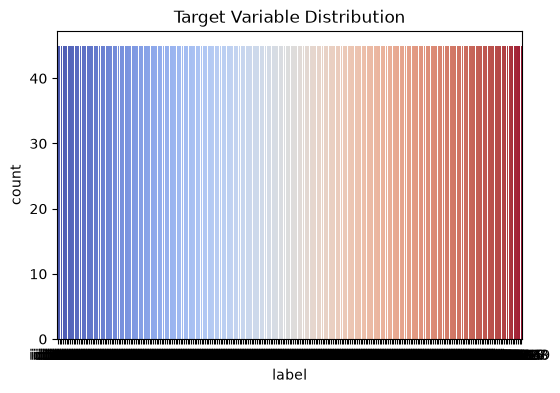

In [7]:
target_col = 'label' 
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target_col, palette="coolwarm")
plt.title("Target Variable Distribution")
plt.show()

Detect numeric columns

In [8]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

Check skewness

In [9]:
print("Skewness before log transformation:")
print(df[numeric_cols].skew().sort_values(ascending=False))

Skewness before log transformation:
f80     1.327269
f81     0.967074
f82     0.557665
f79     0.485278
f127    0.412641
          ...   
f2     -0.441601
f8     -0.445037
f158   -0.467391
f159   -0.470294
f3     -0.610734
Length: 160, dtype: float64


Yeo-Johnson transformation

In [10]:
pt = PowerTransformer(method='yeo-johnson')
df_yeojohnson = pd.DataFrame(pt.fit_transform(df[numeric_cols]), columns=numeric_cols)
print("\nYeo-Johnson transform applied successfully.")


Yeo-Johnson transform applied successfully.


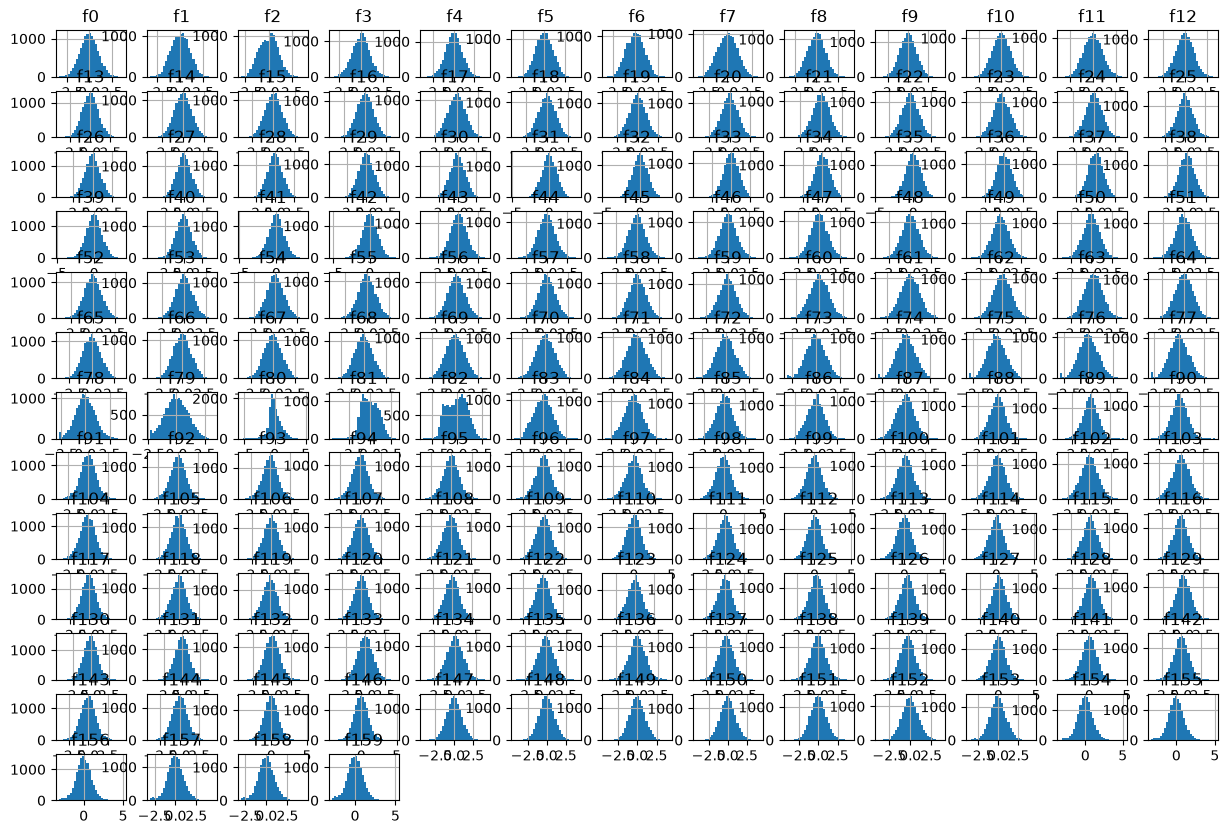

f155    0.058884
f154    0.053804
f156    0.052818
f157    0.046248
f158    0.041734
          ...   
f77    -0.005506
f86    -0.008285
f84    -0.008429
f82    -0.013517
f83    -0.018270
Length: 160, dtype: float64


In [11]:
df_yeojohnson.hist(bins=30, figsize=(15,10))
plt.show()

print(df_yeojohnson.skew().sort_values(ascending=False))

In [12]:
new = pd.concat([df_yeojohnson, df['label']], axis=1)

In [13]:
new.to_csv("new_distributed_data.csv")

Load PCA data 

In [14]:
df = pd.read_csv("new_distributed_data.csv")

x = df.drop(columns=["label"])
y = df["label"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(x)

le = LabelEncoder()
y_encoded = le.fit_transform(y)

Train Test Split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42
)

Model

In [16]:
model = XGBClassifier(
    n_estimators=200,
    eval_metric='logloss', device='cuda'
)

Training

In [17]:
model.fit(X_train, y_train)

d:\Human voice multi classification\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:28:36] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
d:\Human voice multi classification\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:28:36] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True

Pridiction

In [18]:
y_pred = model.predict(X_test)

Evaluation

In [19]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nReport:\n", classification_report(y_test, y_pred))

Accuracy: 0.8917802560925238

Report:
               precision    recall  f1-score   support

           0       0.83      0.83      0.83        12
           1       0.56      0.83      0.67        12
           2       0.86      0.46      0.60        13
           3       0.71      0.83      0.77         6
           4       1.00      0.88      0.93         8
           5       1.00      0.71      0.83         7
           6       0.82      0.90      0.86        10
           7       0.73      1.00      0.84         8
           8       0.80      0.50      0.62         8
           9       0.92      0.92      0.92        13
          10       1.00      1.00      1.00        13
          11       0.75      1.00      0.86         6
          12       1.00      0.92      0.96        13
          13       1.00      1.00      1.00         7
          14       1.00      0.80      0.89         5
          15       0.90      1.00      0.95         9
          16       1.00      1.00      1.0

In [20]:
# Test predictions on holdout test data
# Since X_test is already preprocessed (scaled numpy array), we can predict directly
test_predictions = model.predict(X_test[:10])
test_probabilities = model.predict_proba(X_test[:10])

print("Sample Predictions on Holdout Data (first 10 samples):")
print("Predicted classes:", test_predictions)
print("\nPrediction probabilities:\n", test_probabilities)
print("\nActual values from test set:", y_test[:10])
print("\nMatches (correct predictions):", (test_predictions == y_test[:10]))
print("\nAccuracy on these samples: {:.2%}".format(
    (test_predictions == y_test[:10]).sum() / len(test_predictions)
))

Sample Predictions on Holdout Data (first 10 samples):
Predicted classes: [ 33 184 186 171  69 148 248 152  57 152]

Prediction probabilities:
 [[3.4104185e-05 2.7371510e-05 1.6802773e-05 ... 1.0600645e-04
  1.7907416e-05 3.6798723e-05]
 [1.1695714e-05 5.9872004e-06 3.6770066e-06 ... 4.4960507e-06
  2.0799562e-05 7.6362257e-06]
 [5.2445470e-05 3.5706118e-05 2.2053902e-05 ... 2.9293762e-05
  5.9362512e-05 9.5977754e-05]
 ...
 [4.9780472e-05 1.1077234e-04 6.6944092e-05 ... 7.4812124e-05
  6.4464475e-05 7.9145182e-05]
 [5.5172500e-06 3.4714460e-06 1.6910734e-06 ... 4.6398800e-06
  5.9726285e-06 9.6504591e-06]
 [3.3740478e-04 2.3239492e-04 4.9744477e-04 ... 2.1024885e-04
  4.3560151e-04 3.4069101e-04]]

Actual values from test set: [ 32 184 186 171  69 148 248 152  57 152]

Matches (correct predictions): [False  True  True  True  True  True  True  True  True  True]

Accuracy on these samples: 90.00%


Test on Holdout Data

In [51]:
def preprocess_new_data(new_data, scaler, pt, le, numeric_cols, cat_cols):
    """
    Preprocess new data using the saved preprocessing objects
    
    Parameters:
    - new_data: DataFrame with the same features as training data
    - scaler: Fitted StandardScaler
    - pt: Fitted PowerTransformer
    - le: Fitted LabelEncoder
    - numeric_cols: List of numeric column names
    - cat_cols: List of categorical column names
    
    Returns:
    - Preprocessed data ready for prediction
    """
    # Make a copy to avoid modifying original
    data = new_data.copy()
    
    # Encode categorical variables
    for col in cat_cols:
        if col in data.columns:
            data[col] = le.transform(data[col].astype(str))
    
    # Apply power transformation to numeric columns
    if len(numeric_cols) > 0:
        data[numeric_cols] = pt.transform(data[numeric_cols])
    
    # Scale the data
    data_scaled = scaler.transform(data)
    
    return data_scaled

def predict_new_samples(new_data, model, scaler, pt, le, numeric_cols, cat_cols):
    """
    Make predictions on new data
    
    Parameters:
    - new_data: DataFrame with new samples
    - model: Trained XGBoost model
    - scaler, pt, le: Fitted preprocessing objects
    - numeric_cols, cat_cols: Column names
    
    Returns:
    - Predictions and prediction probabilities
    """
    preprocessed_data = preprocess_new_data(new_data, scaler, pt, le, numeric_cols, cat_cols)
    predictions = model.predict(preprocessed_data)
    probabilities = model.predict_proba(preprocessed_data)
    
    return predictions, probabilities

print("Prediction functions created!")

Prediction functions created!


Prediction Function for New Data

In [21]:
import joblib
import os

# Create a models directory if it doesn't exist
os.makedirs('../models', exist_ok=True)

# Save the trained model
joblib.dump(model, '../models/xgboost_model.pkl')

# Also save the preprocessing objects
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(pt, '../models/power_transformer.pkl')
joblib.dump(le, '../models/label_encoder.pkl')

print("Model and preprocessing objects saved successfully!")

Model and preprocessing objects saved successfully!


Model Deployment

In [22]:
import json
from datetime import datetime

# Create model metadata
metadata = {
    'model_type': 'XGBClassifier',
    'created_date': datetime.now().isoformat(),
    'training_set_size': len(X_train),
    'test_set_size': len(X_test),
    'number_of_features': X_train.shape[1],
    'number_of_classes': len(np.unique(y_encoded)),
    'model_accuracy': float(accuracy_score(y_test, y_pred)),
    'preprocessing': {
        'scaler': 'StandardScaler',
        'transformer': 'PowerTransformer (Yeo-Johnson)',
        'label_encoder': 'LabelEncoder'
    },
    'features': {
        'numeric': list(numeric_cols),
        'categorical': list(cat_cols)
    }
}

# Save metadata to JSON
with open('../models/model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)

print("Model Metadata:")
for key, value in metadata.items():
    if isinstance(value, dict):
        print(f"  {key}:")
        for k, v in value.items():
            print(f"    - {k}: {v}")
    else:
        print(f"  {key}: {value}")

Model Metadata:
  model_type: XGBClassifier
  created_date: 2026-10-28T23:32:53.968833
  training_set_size: 9684
  test_set_size: 2421
  number_of_features: 161
  number_of_classes: 269
  model_accuracy: 0.8917802560925238
  preprocessing:
    - scaler: StandardScaler
    - transformer: PowerTransformer (Yeo-Johnson)
    - label_encoder: LabelEncoder
  features:
    - numeric: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'f12', 'f13', 'f14', 'f15', 'f16', 'f17', 'f18', 'f19', 'f20', 'f21', 'f22', 'f23', 'f24', 'f25', 'f26', 'f27', 'f28', 'f29', 'f30', 'f31', 'f32', 'f33', 'f34', 'f35', 'f36', 'f37', 'f38', 'f39', 'f40', 'f41', 'f42', 'f43', 'f44', 'f45', 'f46', 'f47', 'f48', 'f49', 'f50', 'f51', 'f52', 'f53', 'f54', 'f55', 'f56', 'f57', 'f58', 'f59', 'f60', 'f61', 'f62', 'f63', 'f64', 'f65', 'f66', 'f67', 'f68', 'f69', 'f70', 'f71', 'f72', 'f73', 'f74', 'f75', 'f76', 'f77', 'f78', 'f79', 'f80', 'f81', 'f82', 'f83', 'f84', 'f85', 'f86', 'f87', 'f88', 'f89',

In [23]:
import os
import json
import joblib
from datetime import datetime

SAVE_DIR = r"D:\Human voice multi classification\saved_models"
os.makedirs(SAVE_DIR, exist_ok=True)

# Yahan apne variable ke naam likho. Jo exist karega wahi save hoga.
# (naam jo file mein banega, variable ka naam)
objects_to_save = {
    "xgb_model": "model",          # trained model
    "scaler": "scaler",            # StandardScaler
    "label_encoder": "le",         # LabelEncoder
    "power_transformer": "pt",     # PowerTransformer (agar use kiya ho)
}

saved, skipped = [], []
for file_name, var_name in objects_to_save.items():
    if var_name in globals():
        joblib.dump(globals()[var_name], os.path.join(SAVE_DIR, f"{file_name}.pkl"))
        saved.append(file_name)
    else:
        skipped.append(f"{file_name} (variable '{var_name}' nahi mila)")

# Feature columns ka order bhi save karo (baad mein predict karte waqt zaroori hota hai)
if "numeric_cols" in globals():
    with open(os.path.join(SAVE_DIR, "feature_columns.json"), "w") as f:
        json.dump(list(numeric_cols), f)
    saved.append("feature_columns")

# Run ka time note kar lo
with open(os.path.join(SAVE_DIR, "last_saved.json"), "w") as f:
    json.dump({"saved_at": datetime.now().isoformat(), "files": saved}, f, indent=2)

print("Saved in:", SAVE_DIR)
print("Saved :", saved)
print("Skipped:", skipped)

Saved in: D:\Human voice multi classification\saved_models
Saved : ['xgb_model', 'scaler', 'label_encoder', 'power_transformer', 'feature_columns']
Skipped: []


Model Metadata & Summary

In [24]:
# Create a standalone prediction script file
deployment_script = '''
import joblib
import numpy as np
import pandas as pd

class ModelPredictor:
    """Standalone model predictor for deployment"""
    
    def __init__(self, model_path='xgboost_model.pkl', 
                 scaler_path='scaler.pkl',
                 pt_path='power_transformer.pkl',
                 le_path='label_encoder.pkl'):
        """Load all necessary model artifacts"""
        self.model = joblib.load(model_path)
        self.scaler = joblib.load(scaler_path)
        self.pt = joblib.load(pt_path)
        self.le = joblib.load(le_path)
        print("Model artifacts loaded successfully!")
    
    def predict(self, X_preprocessed):
        """Make predictions on preprocessed data"""
        predictions = self.model.predict(X_preprocessed)
        probabilities = self.model.predict_proba(X_preprocessed)
        return predictions, probabilities
    
    def predict_proba(self, X_preprocessed):
        """Get prediction probabilities"""
        return self.model.predict_proba(X_preprocessed)

# Example usage:
if __name__ == "__main__":
    predictor = ModelPredictor()
    # Example: predictor.predict(your_preprocessed_data)
'''

# Save the deployment script with UTF-8 encoding
with open('../models/predictor.py', 'w', encoding='utf-8') as f:
    f.write(deployment_script)

print("Deployment script created at ../models/predictor.py")

Deployment script created at ../models/predictor.py


Create Deployment Script

In [25]:
# Load saved model and preprocessing objects
loaded_model = joblib.load('../models/xgboost_model.pkl')
loaded_scaler = joblib.load('../models/scaler.pkl')
loaded_pt = joblib.load('../models/power_transformer.pkl')
loaded_le = joblib.load('../models/label_encoder.pkl')

print("Model loaded successfully!")
print(f"Model type: {type(loaded_model)}")
print(f"Model parameters:\n{loaded_model.get_params()}")

# Verify model works by testing on the test set
y_pred_loaded = loaded_model.predict(X_test[:5])
print(f"\nTest predictions from loaded model: {y_pred_loaded}")
print(f"Original predictions: {y_pred[:5]}")
print(f"Match: {np.array_equal(y_pred_loaded, y_pred[:5])}")

Model loaded successfully!
Model type: <class 'xgboost.sklearn.XGBClassifier'>
Model parameters:
{'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': 'cuda', 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 200, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': None, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters':